# Тема 2. Онтологии и связанные данные
## Семинар 1. Публичные словари и концептуальная модель

In [1]:
%pip install rdflib
from IPython.display import display, HTML, SVG
from pathlib import Path
from urllib.parse import quote
import html as _html
import json

try:
    import rdflib
    from rdflib import Graph, Namespace, URIRef, Literal
    from rdflib.namespace import RDF, RDFS, XSD
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "Для этого семинара требуется RDFLib. "
        "Установите пакет отдельной ячейкой: %pip install rdflib"
    ) from exc

print("RDFLib:", rdflib.__version__)

def show_table(headers, rows):
    """Аккуратно выводит таблицу и переносит длинный текст внутри ячеек."""
    head = "".join(f"<th>{_html.escape(str(h))}</th>" for h in headers)
    body = []
    for row in rows:
        body.append(
            "<tr>" +
            "".join(f"<td>{_html.escape(str(v))}</td>" for v in row) +
            "</tr>"
        )
    display(HTML(
        '<div style="overflow-x:auto; margin:8px 0 18px 0;">'
        '<table style="border-collapse:collapse; width:100%; table-layout:auto; font-size:14px;">'
        '<thead><tr>' + head + '</tr></thead>'
        '<tbody>' + "".join(body) + '</tbody></table></div>'
        '<style>'
        'table th, table td {border:1px solid #bbb; padding:7px 9px; vertical-align:top;'
        'white-space:normal; overflow-wrap:anywhere; line-height:1.35;}'
        'table th {font-weight:600; background:#f5f5f5;}'
        '</style>'
    ))

def show_sparql_result(graph, query, max_rows=30):
    """Выполняет настоящий SPARQL средствами RDFLib и показывает результат."""
    result = graph.query(query)

    if getattr(result, "type", None) == "ASK":
        print("Результат ASK:", bool(result.askAnswer))
        return result

    if getattr(result, "type", None) in ("CONSTRUCT", "DESCRIBE"):
        out_graph = result.graph
        print("Получено RDF-троек:", len(out_graph))
        print(out_graph.serialize(format="turtle"))
        return result

    headers = [str(v) for v in result.vars]
    rows = []
    for idx, row in enumerate(result):
        if idx >= max_rows:
            break
        rows.append(["" if v is None else str(v) for v in row])

    show_table(headers, rows)
    if not rows:
        print("Запрос выполнен, строк результата нет.")
    return result


[notice] A new release of pip is available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


RDFLib: 7.6.0


**Работа с `.ttl`-файлами на этом семинаре.**

На Семинаре 1 создаётся **черновой Turtle-файл концептуальной модели**. Он служит переходом к Семинару 2, где схема и данные будут формализованы подробнее в RDFS/OWL.

Пошаговая работа:

1. сформулировать назначение, границы и компетентностные вопросы;
2. определить классы, экземпляры, объектные свойства и свойства данных;
3. выбрать пространство имён и правила именования;
4. записать минимальный Turtle-черновик;
5. сохранить его как `ontology_draft.ttl` в UTF-8;
6. положить файл в ту же папку, где находится notebook;
7. выполнить проверочную ячейку ниже;
8. после изменения `.ttl` снова выполнить ячейки, которые работают с графом;
9. сохранить `ontology_draft.ttl` для Семинара 2.

В notebook предусмотрена **резервная кнопка** скачивания `ontology_draft.ttl`. Если собственный файл после работы уже существует, скачивать образец не нужно.

In [2]:
ONTOLOGY_DRAFT_TEMPLATE = r"""
@prefix uni: <https://example.org/university/> .
@prefix rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix schema: <https://schema.org/> .

# --- Черновые классы ---
uni:Person a rdfs:Class ;
    rdfs:subClassOf schema:Person ;
    rdfs:label "Человек"@ru .

uni:Student a rdfs:Class ;
    rdfs:subClassOf uni:Person ;
    rdfs:label "Студент"@ru .

uni:Teacher a rdfs:Class ;
    rdfs:subClassOf uni:Person ;
    rdfs:label "Преподаватель"@ru .

uni:Organization a rdfs:Class ;
    rdfs:subClassOf schema:Organization ;
    rdfs:label "Организация"@ru .

uni:Department a rdfs:Class ;
    rdfs:subClassOf uni:Organization ;
    rdfs:label "Кафедра"@ru .

uni:University a rdfs:Class ;
    rdfs:subClassOf uni:Organization ;
    rdfs:label "Университет"@ru .

uni:EducationalEntity a rdfs:Class ;
    rdfs:label "Образовательная сущность"@ru .

uni:Course a rdfs:Class ;
    rdfs:subClassOf uni:EducationalEntity , schema:Course ;
    rdfs:label "Учебный курс"@ru .

uni:CourseInstance a rdfs:Class ;
    rdfs:subClassOf uni:EducationalEntity , schema:CourseInstance ;
    rdfs:label "Проведение курса"@ru .

uni:EducationalProgram a rdfs:Class ;
    rdfs:subClassOf uni:EducationalEntity ;
    rdfs:label "Образовательная программа"@ru .

uni:Enrollment a rdfs:Class ;
    rdfs:label "Зачисление на проведение курса"@ru .

# --- Черновые свойства ---
uni:studiesCourse a rdf:Property ;
    rdfs:domain uni:Student ;
    rdfs:range uni:Course ;
    rdfs:label "изучает курс"@ru .

uni:teachesCourse a rdf:Property ;
    rdfs:domain uni:Teacher ;
    rdfs:range uni:Course ;
    rdfs:label "ведёт курс"@ru .

uni:hasCourseInstance a rdf:Property ;
    rdfs:domain uni:Course ;
    rdfs:range uni:CourseInstance ;
    rdfs:label "имеет проведение"@ru .

uni:partOfProgram a rdf:Property ;
    rdfs:domain uni:Course ;
    rdfs:range uni:EducationalProgram ;
    rdfs:label "входит в программу"@ru .

uni:memberOfDepartment a rdf:Property ;
    rdfs:domain uni:Person ;
    rdfs:range uni:Department ;
    rdfs:label "относится к кафедре"@ru .

uni:partOfUniversity a rdf:Property ;
    rdfs:domain uni:Department ;
    rdfs:range uni:University ;
    rdfs:label "входит в университет"@ru .

uni:hasEnrollment a rdf:Property ;
    rdfs:domain uni:Student ;
    rdfs:range uni:Enrollment ;
    rdfs:label "имеет зачисление"@ru .

uni:forCourseInstance a rdf:Property ;
    rdfs:domain uni:Enrollment ;
    rdfs:range uni:CourseInstance ;
    rdfs:label "относится к проведению курса"@ru .

uni:fullName a rdf:Property ;
    rdfs:domain uni:Person ;
    rdfs:range rdf:langString ;
    rdfs:label "полное имя"@ru .

uni:courseCode a rdf:Property ;
    rdfs:domain uni:Course ;
    rdfs:range xsd:string ;
    rdfs:label "код курса"@ru .

uni:credits a rdf:Property ;
    rdfs:domain uni:Course ;
    rdfs:range xsd:decimal ;
    rdfs:label "зачётные единицы"@ru .

uni:startDate a rdf:Property ;
    rdfs:domain uni:CourseInstance ;
    rdfs:range xsd:date ;
    rdfs:label "дата начала"@ru .

# --- Небольшой набор тестовых экземпляров ---
uni:ExampleUniversity a uni:University ;
    rdfs:label "Примерный университет"@ru .

uni:AIDepartment a uni:Department ;
    rdfs:label "Кафедра искусственного интеллекта"@ru ;
    uni:partOfUniversity uni:ExampleUniversity .

uni:AppliedInformatics a uni:EducationalProgram ;
    rdfs:label "Прикладная информатика"@ru .

uni:SemTech a uni:Course ;
    rdfs:label "Семантические технологии"@ru ;
    uni:courseCode "ST-201" ;
    uni:credits "3"^^xsd:decimal ;
    uni:partOfProgram uni:AppliedInformatics .

uni:SemTech2026Autumn a uni:CourseInstance ;
    rdfs:label "Семантические технологии, осень 2026"@ru ;
    uni:startDate "2026-09-01"^^xsd:date .

uni:SemTech uni:hasCourseInstance uni:SemTech2026Autumn .

uni:Anna a uni:Student ;
    uni:fullName "Анна Смирнова"@ru ;
    uni:studiesCourse uni:SemTech ;
    uni:memberOfDepartment uni:AIDepartment .

uni:Petrova a uni:Teacher ;
    uni:fullName "Елена Петрова"@ru ;
    uni:teachesCourse uni:SemTech ;
    uni:memberOfDepartment uni:AIDepartment .

uni:AnnaEnrollment a uni:Enrollment ;
    uni:forCourseInstance uni:SemTech2026Autumn .

uni:Anna uni:hasEnrollment uni:AnnaEnrollment .
"""

In [3]:
from pathlib import Path
from urllib.parse import quote
from IPython.display import display, HTML

def ttl_download_button(filename, text, label=None):
    label = label or f"Скачать {filename}"
    href = "data:text/turtle;charset=utf-8," + quote(text)
    display(HTML(
        '<a download="' + filename + '" href="' + href + '" '
        'style="display:inline-block;padding:7px 11px;margin:3px 6px 3px 0;'
        'border:1px solid #777;border-radius:6px;text-decoration:none;">'
        + _html.escape(label) + '</a>'
    ))

def load_turtle_graph(filename, fallback_text=None):
    """Загружает Turtle только средствами RDFLib."""
    p = Path(filename)
    graph = Graph()

    if p.exists():
        text = p.read_text(encoding="utf-8")
        source = "локальный файл"
        found = True
    elif fallback_text is not None:
        text = fallback_text
        source = "встроенный образец"
        found = False
    else:
        raise FileNotFoundError(f"Файл {filename} не найден.")

    graph.parse(data=text, format="turtle")
    return graph, source, found, text

In [4]:
try:
    draft_graph, draft_source, draft_found, draft_text = load_turtle_graph(
        "ontology_draft.ttl",
        ONTOLOGY_DRAFT_TEMPLATE
    )

    show_table(
        ["Файл", "В папке notebook", "Используется", "Проверка RDFLib", "Число троек"],
        [[
            "ontology_draft.ttl",
            "найден" if draft_found else "не найден",
            draft_source,
            "Turtle разобран без ошибок",
            len(draft_graph)
        ]]
    )
except Exception as exc:
    print("RDFLib обнаружил ошибку в Turtle:")
    print(type(exc).__name__ + ":", exc)
    raise

# Резервная кнопка одна. При наличии собственного файла она не нужна.
ttl_download_button(
    "ontology_draft.ttl",
    ONTOLOGY_DRAFT_TEMPLATE,
    "Скачать резервный ontology_draft.ttl"
)

Файл,В папке notebook,Используется,Проверка RDFLib,Число троек
ontology_draft.ttl,найден,локальный файл,Turtle разобран без ошибок,148


## 1. От словаря терминов к онтологии

Представим три системы, описывающие преподавателя:

```text
Система A: employee_type = "lecturer"
Система B: role = "teacher"
Система C: rdf:type = schema:Person; jobTitle = "доцент"
```

Для человека записи выглядят близкими. Для программы это три разных способа описания которые не позволяют автоматически решить, обозначают ли `lecturer`, `teacher` и `jobTitle = "доцент"` один и тот же тип сущности, роль, должность или разные характеристики.

Чтобы объединять такие данные осмысленно, необходимо заранее определить:

- что считается человеком, сотрудником и преподавателем;
- является ли преподаватель подтипом сотрудника или ролью человека;
- какие свойства относятся к человеку, а какие - к его работе;
- может ли один человек одновременно быть преподавателем и студентом;
- по каким идентификаторам записи из разных систем сопоставляются.

**Онтология** не просто перечисляет названия полей, а фиксирует, какие понятия существуют в предметной области и как они связаны.

В качестве определения онтологии рассмотрим следующее:

> **Онтология - формально заданное и разделяемое описание понятий предметной области, отношений между ними, ограничений и правил интерпретации.**

Слово *формально* означает, что описание записывается на языке с определённым синтаксисом и семантикой, а слово *разделяемое* подчёркивает, что модель предназначена не только для одного автора: её термины и соглашения должны быть понятны другим людям и программам.

Упрощённо онтологию можно представить как:

$$
O = (C, P_o, P_d, I, A)
$$

где:

- $C$ - множество классов;
- $P_o$ - объектные свойства, связывающие ресурсы;
- $P_d$ - свойства данных, связывающие ресурс с литералом;
- $I$ - именованные экземпляры;
- $A$ - аксиомы и ограничения.

В более полной модели отдельно могут присутствовать аннотации, правила, метаданные версий и отображения на внешние словари.

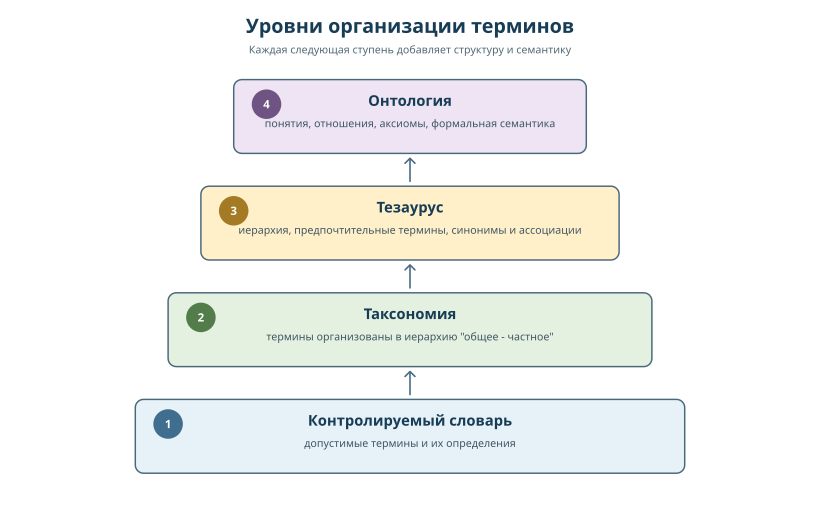

In [5]:
svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="820" height="520" viewBox="0 0 1000 630">
  <rect width="1000" height="630" fill="white"/>
  <defs>
    <marker id="up" markerWidth="10" markerHeight="10" refX="5" refY="5" orient="auto">
      <path d="M0,10 L5,0 L10,10 z" fill="#4b6c82"/>
    </marker>
  </defs>
  <style>
    .box{stroke:#49687b;stroke-width:1.8}
    .title{font:700 18px sans-serif;fill:#173c55;text-anchor:middle}
    .sub{font:13px sans-serif;fill:#3e5563;text-anchor:middle}
    .head{font:700 24px sans-serif;fill:#173c55;text-anchor:middle}
    .note{font:13px sans-serif;fill:#536975;text-anchor:middle}
    .num{font:700 14px sans-serif;fill:white;text-anchor:middle}
  </style>

  <text x="500" y="38" class="head">Уровни организации терминов</text>
  <text x="500" y="63" class="note">Каждая следующая ступень добавляет структуру и семантику</text>

  <rect x="285" y="95" width="430" height="90" rx="10" fill="#eee4f4" class="box"/>
  <circle cx="325" cy="125" r="18" fill="#6f5383"/>
  <text x="325" y="130" class="num">4</text>
  <text x="500" y="127" class="title">Онтология</text>
  <text x="500" y="153" class="sub">понятия, отношения, аксиомы, формальная семантика</text>

  <rect x="245" y="225" width="510" height="90" rx="10" fill="#fff0c9" class="box"/>
  <circle cx="285" cy="255" r="18" fill="#a47a24"/>
  <text x="285" y="260" class="num">3</text>
  <text x="500" y="257" class="title">Тезаурус</text>
  <text x="500" y="283" class="sub">иерархия, предпочтительные термины, синонимы и ассоциации</text>

  <rect x="205" y="355" width="590" height="90" rx="10" fill="#e4f1e1" class="box"/>
  <circle cx="245" cy="385" r="18" fill="#527d4a"/>
  <text x="245" y="390" class="num">2</text>
  <text x="500" y="387" class="title">Таксономия</text>
  <text x="500" y="413" class="sub">термины организованы в иерархию "общее - частное"</text>

  <rect x="165" y="485" width="670" height="90" rx="10" fill="#e7f1f8" class="box"/>
  <circle cx="205" cy="515" r="18" fill="#3f6e8e"/>
  <text x="205" y="520" class="num">1</text>
  <text x="500" y="517" class="title">Контролируемый словарь</text>
  <text x="500" y="543" class="sub">допустимые термины и их определения</text>

  <!-- Ровные одинаковые стрелки по общей вертикальной оси -->
  <path d="M500 479 V451 M494 457 L500 451 L506 457" fill="none" stroke="#4b6c82" stroke-width="2" stroke-linecap="round" stroke-linejoin="round"/>
  <path d="M500 349 V321 M494 327 L500 321 L506 327" fill="none" stroke="#4b6c82" stroke-width="2" stroke-linecap="round" stroke-linejoin="round"/>
  <path d="M500 219 V191 M494 197 L500 191 L506 197" fill="none" stroke="#4b6c82" stroke-width="2" stroke-linecap="round" stroke-linejoin="round"/>
</svg>
"""
display(SVG(svg))

Схема показывает **уровни организации терминов**.

**Контролируемый словарь** задаёт допустимые термины и определения. Он помогает избежать вариантов написания, но сам по себе может не показывать связи между понятиями.

**Таксономия** добавляет иерархию "общее - частное". Она полезна для классификации и навигации, но обычно не описывает произвольные отношения вроде "преподаватель ведёт курс".

**Тезаурус** дополняет иерархию предпочтительными терминами, синонимами и ассоциативными связями. Для публикации подобных моделей часто используется SKOS.

**Онтология** позволяет перейти от организации терминов к описанию классов, свойств, иерархий и формальной семантики. При необходимости она включает эквивалентность, несовместимость и другие аксиомы.

Как было отмечено ранее, необходимо различать:

$$
KG = TBox \cup ABox
$$

где **TBox** содержит терминологическую часть: классы, свойства и общие аксиомы, а **ABox** содержит утверждения о конкретных экземплярах.

Например:

```turtle
# TBox
uni:Student rdfs:subClassOf uni:Person .
uni:studiesCourse rdfs:domain uni:Student ;
                  rdfs:range  uni:Course .

# ABox
uni:Anna a uni:Student ;
         uni:studiesCourse uni:SemTech .
```
`uni:` - это короткий префикс пространства имён университетского примера. Он не является отдельным протоколом или командой. Запись

```text
uni:Student
```

разворачивается в полный IRI:

```text
https://example.org/university/Student
```

После того как определены уровни модели, можно перейти к её внутренним компонентам: классам, экземплярам, свойствам и аксиомам.

In [6]:
show_table(
    ["Артефакт", "Что фиксирует", "Типичная задача"],
    [
        ["Словарь", "допустимые термины и определения", "единая терминология"],
        ["Таксономия", "иерархию понятий", "классификация и навигация"],
        ["Тезаурус", "иерархию, синонимы и ассоциации", "тематический поиск"],
        ["Схема данных", "структуру записей и типы полей", "хранение и обмен"],
        ["Онтология", "понятия, отношения и формальную семантику", "интеграция, вывод, переиспользование"],
    ]
)

Артефакт,Что фиксирует,Типичная задача
Словарь,допустимые термины и определения,единая терминология
Таксономия,иерархию понятий,классификация и навигация
Тезаурус,"иерархию, синонимы и ассоциации",тематический поиск
Схема данных,структуру записей и типы полей,хранение и обмен
Онтология,"понятия, отношения и формальную семантику","интеграция, вывод, переиспользование"


In [7]:
# Пример TBox: выбираем явные отношения подкласса.

query_tbox = """
PREFIX uni:  <https://example.org/university/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?child ?parent
WHERE {
  ?child rdfs:subClassOf ?parent .
  FILTER(STRSTARTS(STR(?child), STR(uni:)))
}
ORDER BY ?child
"""
show_sparql_result(draft_graph, query_tbox)

child,parent


Запрос выполнен, строк результата нет.


## 2. Компоненты модели и онтологическое обязательство

### Классы и экземпляры

**Класс** объединяет сущности, которые рассматриваются как экземпляры одного понятия. `Student`, `Teacher`, `Course` и `Department` являются классами.

Важно отличать класс от множества записей в конкретной базе. Класс задаёт понятие, а его фактическое расширение может изменяться. 

Классы образуют иерархию. Например, запись

```turtle
uni:Student rdfs:subClassOf uni:Person .
```

читается: класс `Student` является подклассом `Person`. Иерархия должна выражать отношение «каждый экземпляр дочернего класса является экземпляром родительского». Если это утверждение не выполняется для всех экземпляров, то данная связь не является отношением подкласса.

Для отношения подкласса применяется простой тест:

> Верно ли, что **каждый** экземпляр класса A является экземпляром класса B?

Формально:

$$
x \in A \land A \subseteq B \Rightarrow x \in B
$$

Поэтому:

- "каждый студент является человеком" подходит для `subClassOf`;
- "каждый курс входит в программу" не подходит: курс не является программой, между ними требуется отдельное отношение.

**Экземпляр** обозначает конкретный объект: Анну Смирнову, курс текущего учебного года, определённую кафедру. Экземпляр связывается с классом через `rdf:type`:

```turtle
uni:Anna rdf:type uni:Student .
uni:SemTech rdf:type uni:Course .
```


### Свойства

**Объектное свойство** связывает один ресурс с другим:

```turtle
uni:Anna uni:studiesCourse uni:SemTech .
```

**Свойство данных** связывает ресурс с литералом:

```turtle
uni:SemTech uni:credits "3"^^xsd:decimal .
```

**Аннотации** документируют модель и не обязательно участвуют в предметном выводе:

```turtle
uni:Student rdfs:label "Студент"@ru ;
            rdfs:comment "Лицо, зачисленное на образовательную программу"@ru .
```

Метки, комментарии, определения, авторство и версии делают онтологию понятной не только программам, но и людям.

**Аксиомы** фиксируют общие утверждения и превращают перечень терминов в формальную модель.

Следующая таблица сводит эти элементы вместе, а затем тот же набор будет показан в виде фрагмента университетской онтологии.

In [8]:
show_table(
    ["Компонент", "Пример", "Смысл"],
    [
        ["Класс", "Student", "понятие: множество потенциальных студентов"],
        ["Экземпляр", "Анна Смирнова", "конкретный человек"],
        ["Объектное свойство", "изучает курс", "ресурс → ресурс"],
        ["Свойство данных", "зачётные единицы", "ресурс → литерал"],
        ["Аннотация", "русская метка", "документация модели"],
        ["Аксиома", "Student ⊆ Person", "общее утверждение"],
    ]
)

Компонент,Пример,Смысл
Класс,Student,понятие: множество потенциальных студентов
Экземпляр,Анна Смирнова,конкретный человек
Объектное свойство,изучает курс,ресурс → ресурс
Свойство данных,зачётные единицы,ресурс → литерал
Аннотация,русская метка,документация модели
Аксиома,Student ⊆ Person,общее утверждение


### Фрагмент онтологии университета

Указанный рисунок представляет собой концептуальный каркас, который отвечает на несколько ключевых вопросов: какие типы сущностей существуют, какие из них являются более частными, и какие отношения связывают экземпляры этих классов. Например, `Student` и `Teacher` являются частными случаями `Person`, а `Course` и `EducationalProgram` относятся к образовательным сущностям. Свойство `studiesCourse` связывает студента с курсом, `teachesCourse` - преподавателя с курсом, `partOfProgram` - курс с программой, а `memberOfDepartment` - человека с кафедрой.

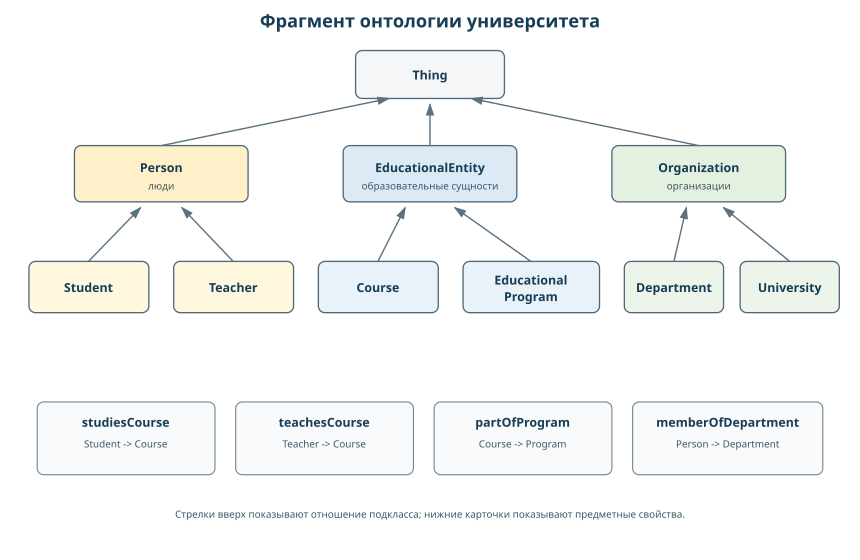

In [9]:
svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="860" height="560" viewBox="0 0 1040 675">
  <rect width="1040" height="675" fill="white"/>
  <defs>
    <marker id="arr" markerWidth="10" markerHeight="10" refX="8" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#5a7180"/>
    </marker>
  </defs>
  <style>
    .box{stroke:#4f6879;stroke-width:1.6}
    .t{font:700 15px sans-serif;fill:#173c55;text-anchor:middle}
    .s{font:12px sans-serif;fill:#3e5664;text-anchor:middle}
    .h{font:700 22px sans-serif;fill:#173c55;text-anchor:middle}
    .edge{stroke:#5a7180;stroke-width:1.7;marker-end:url(#arr)}
    .prop{stroke:#758a97;stroke-width:1.4}
  </style>
  <text x="520" y="32" class="h">Фрагмент онтологии университета</text>

  <rect x="430" y="60" width="180" height="58" rx="8" fill="#f4f6f8" class="box"/>
  <text x="520" y="95" class="t">Thing</text>

  <rect x="90" y="175" width="210" height="68" rx="8" fill="#fff0c9" class="box"/>
  <text x="195" y="207" class="t">Person</text>
  <text x="195" y="228" class="s">люди</text>

  <rect x="415" y="175" width="210" height="68" rx="8" fill="#dceaf5" class="box"/>
  <text x="520" y="207" class="t">EducationalEntity</text>
  <text x="520" y="228" class="s">образовательные сущности</text>

  <rect x="740" y="175" width="210" height="68" rx="8" fill="#e4f1e1" class="box"/>
  <text x="845" y="207" class="t">Organization</text>
  <text x="845" y="228" class="s">организации</text>

  <rect x="35" y="315" width="145" height="62" rx="8" fill="#fff8df" class="box"/>
  <text x="107" y="352" class="t">Student</text>

  <rect x="210" y="315" width="145" height="62" rx="8" fill="#fff8df" class="box"/>
  <text x="282" y="352" class="t">Teacher</text>

  <rect x="385" y="315" width="145" height="62" rx="8" fill="#e9f2f8" class="box"/>
  <text x="457" y="352" class="t">Course</text>

  <rect x="560" y="315" width="165" height="62" rx="8" fill="#e9f2f8" class="box"/>
  <text x="642" y="343" class="t">Educational</text>
  <text x="642" y="363" class="t">Program</text>

  <rect x="755" y="315" width="120" height="62" rx="8" fill="#edf5eb" class="box"/>
  <text x="815" y="352" class="t">Department</text>

  <rect x="895" y="315" width="120" height="62" rx="8" fill="#edf5eb" class="box"/>
  <text x="955" y="352" class="t">University</text>

  <line x1="195" y1="175" x2="470" y2="118" class="edge"/>
  <line x1="520" y1="175" x2="520" y2="125" class="edge"/>
  <line x1="845" y1="175" x2="570" y2="118" class="edge"/>

  <line x1="107" y1="315" x2="170" y2="250" class="edge"/>
  <line x1="282" y1="315" x2="220" y2="250" class="edge"/>
  <line x1="457" y1="315" x2="490" y2="250" class="edge"/>
  <line x1="642" y1="315" x2="550" y2="250" class="edge"/>
  <line x1="815" y1="315" x2="830" y2="250" class="edge"/>
  <line x1="955" y1="315" x2="875" y2="250" class="edge"/>

  <rect x="45" y="485" width="215" height="88" rx="8" fill="#f8fafb" class="prop"/>
  <text x="152" y="515" class="t">studiesCourse</text>
  <text x="152" y="540" class="s">Student -> Course</text>

  <rect x="285" y="485" width="215" height="88" rx="8" fill="#f8fafb" class="prop"/>
  <text x="392" y="515" class="t">teachesCourse</text>
  <text x="392" y="540" class="s">Teacher -> Course</text>

  <rect x="525" y="485" width="215" height="88" rx="8" fill="#f8fafb" class="prop"/>
  <text x="632" y="515" class="t">partOfProgram</text>
  <text x="632" y="540" class="s">Course -> Program</text>

  <rect x="765" y="485" width="230" height="88" rx="8" fill="#f8fafb" class="prop"/>
  <text x="880" y="515" class="t">memberOfDepartment</text>
  <text x="880" y="540" class="s">Person -> Department</text>

  <text x="520" y="625" class="s">Стрелки вверх показывают отношение подкласса; нижние карточки показывают предметные свойства.</text>
</svg>
"""
display(SVG(svg))

### Онтологическое обязательство

**Онтологическое обязательство** - совокупность принятых предположений о том, какие сущности и различия модели считаются существенными и как следует интерпретировать её термины.

Например, слово "курс" можно понимать как:

1. абстрактную дисциплину независимо от года;
2. конкретное проведение дисциплины в семестре;
3. набор учебных материалов;
4. мероприятие с расписанием и участниками.

Все варианты возможны, но отвечают на разные вопросы. Если смешать их в одном классе `Course`, появятся свойства разных уровней: у абстрактной дисциплины нет конкретной даты начала, а у проведения в определённом семестре она есть. Поэтому в университетском примере полезно различать `Course` и `CourseInstance`.

**Принцип минимального онтологического обязательства** рекомендует не вводить различия и ограничения, которые не требуются задачей. Модель должна быть достаточно точной для компетентностных вопросов, но не перегруженной предположениями.


## 3. Компетентностные вопросы и переиспользование словарей

Даже аккуратно выделенный набор классов и свойств ещё не гарантирует, что модель полезна - необходим критерий: **на какие вопросы должна отвечать будущая система?** Для этого используются компетентностные вопросы.

**Компетентностный вопрос** - вопрос, на который система должна уметь ответить после реализации онтологии. Он связывает предметные требования с будущими RDF-данными и SPARQL-запросами.

Примеры:

- какие курсы изучает конкретный студент;
- какие преподаватели ведут курсы программы;
- на какой кафедре работает преподаватель;
- у каких курсов отсутствует описание;
- какие лица одновременно относятся к нескольким ролям;
- какие ресурсы связаны с внешними идентификаторами.

Хороший набор включает:

- простые выборки;
- цепочки из двух и более отношений;
- вопросы об отсутствующих данных;
- вопросы, использующие иерархию классов;
- вопросы, для которых в дальнейшем нужен логический вывод;
- вопросы интеграции с внешними источниками.

Для каждого вопроса полезно нарисовать путь по модели. Если такого пути нет, нужно добавить свойство, изменить границы модели или уточнить сам вопрос.


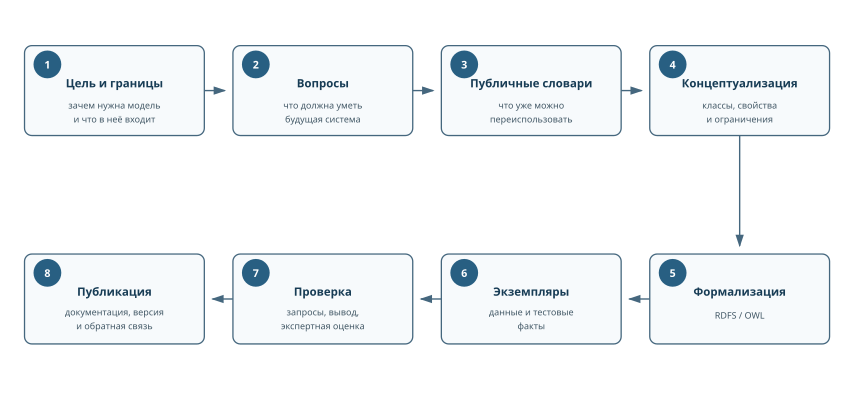

In [10]:
svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="850" height="410" viewBox="0 0 1040 500">
  <rect width="1040" height="500" fill="white"/>
  <defs>
    <marker id="a3" markerWidth="10" markerHeight="10" refX="8" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#45677e"/>
    </marker>
  </defs>
  <style>
    .b{fill:#f7fafc;stroke:#45677e;stroke-width:1.6}
    .n{fill:#285f82}
    .nt{font:700 13px sans-serif;fill:white;text-anchor:middle}
    .t{font:700 14px sans-serif;fill:#173c55;text-anchor:middle}
    .s{font:11px sans-serif;fill:#415765;text-anchor:middle}
    .e{stroke:#45677e;stroke-width:1.7;marker-end:url(#a3)}
  </style>

  <rect x="30" y="55" width="220" height="110" rx="9" class="b"/>
  <circle cx="58" cy="78" r="17" class="n"/><text x="58" y="83" class="nt">1</text>
  <text x="140" y="106" class="t">Цель и границы</text>
  <text x="140" y="132" class="s">зачем нужна модель</text>
  <text x="140" y="149" class="s">и что в неё входит</text>

  <rect x="285" y="55" width="220" height="110" rx="9" class="b"/>
  <circle cx="313" cy="78" r="17" class="n"/><text x="313" y="83" class="nt">2</text>
  <text x="395" y="106" class="t">Вопросы</text>
  <text x="395" y="132" class="s">что должна уметь</text>
  <text x="395" y="149" class="s">будущая система</text>

  <rect x="540" y="55" width="220" height="110" rx="9" class="b"/>
  <circle cx="568" cy="78" r="17" class="n"/><text x="568" y="83" class="nt">3</text>
  <text x="650" y="106" class="t">Публичные словари</text>
  <text x="650" y="132" class="s">что уже можно</text>
  <text x="650" y="149" class="s">переиспользовать</text>

  <rect x="795" y="55" width="220" height="110" rx="9" class="b"/>
  <circle cx="823" cy="78" r="17" class="n"/><text x="823" y="83" class="nt">4</text>
  <text x="905" y="106" class="t">Концептуализация</text>
  <text x="905" y="132" class="s">классы, свойства</text>
  <text x="905" y="149" class="s">и ограничения</text>

  <rect x="795" y="310" width="220" height="110" rx="9" class="b"/>
  <circle cx="823" cy="333" r="17" class="n"/><text x="823" y="338" class="nt">5</text>
  <text x="905" y="361" class="t">Формализация</text>
  <text x="905" y="389" class="s">RDFS / OWL</text>

  <rect x="540" y="310" width="220" height="110" rx="9" class="b"/>
  <circle cx="568" cy="333" r="17" class="n"/><text x="568" y="338" class="nt">6</text>
  <text x="650" y="361" class="t">Экземпляры</text>
  <text x="650" y="385" class="s">данные и тестовые</text>
  <text x="650" y="402" class="s">факты</text>

  <rect x="285" y="310" width="220" height="110" rx="9" class="b"/>
  <circle cx="313" cy="333" r="17" class="n"/><text x="313" y="338" class="nt">7</text>
  <text x="395" y="361" class="t">Проверка</text>
  <text x="395" y="385" class="s">запросы, вывод,</text>
  <text x="395" y="402" class="s">экспертная оценка</text>

  <rect x="30" y="310" width="220" height="110" rx="9" class="b"/>
  <circle cx="58" cy="333" r="17" class="n"/><text x="58" y="338" class="nt">8</text>
  <text x="140" y="361" class="t">Публикация</text>
  <text x="140" y="385" class="s">документация, версия</text>
  <text x="140" y="402" class="s">и обратная связь</text>

  <line x1="250" y1="110" x2="275" y2="110" class="e"/>
  <line x1="505" y1="110" x2="530" y2="110" class="e"/>
  <line x1="760" y1="110" x2="785" y2="110" class="e"/>
  <line x1="905" y1="165" x2="905" y2="300" class="e"/>
  <line x1="795" y1="365" x2="770" y2="365" class="e"/>
  <line x1="540" y1="365" x2="515" y2="365" class="e"/>
  <line x1="285" y1="365" x2="260" y2="365" class="e"/>
</svg>
"""
display(SVG(svg))

Разработка онтологии выполняется итерационно.

**Алгоритм построения прикладной онтологии:**

1. определить назначение модели и пользователей;
2. зафиксировать границы предметной области;
3. сформулировать 8-15 компетентностных вопросов;
4. собрать термины из документов, интерфейсов, БД и общения с экспертами;
5. найти публичные словари и онтологии, описывающие общие понятия;
6. разделить термины на классы, экземпляры, свойства и значения;
7. построить черновую иерархию классов;
8. для каждого свойства определить смысл, предполагаемый домен, диапазон и пример;
9. назначить устойчивые IRI и правила именования;
10. формализовать модель в RDFS или OWL;
11. добавить небольшой набор экземпляров;
12. проверить модель запросами и ожидаемыми выводами;
13. провести экспертное обсуждение;
14. документировать версию и решения;
15. повторять цикл при появлении новых требований.


### Как выделять классы и свойства

При первом прочтении предметного описания удобно использовать лингвистическую подсказку:

- существительные часто становятся кандидатами в классы или экземпляры;
- глаголы и глагольные конструкции часто становятся кандидатами в объектные свойства;
- числовые, текстовые и временные характеристики часто становятся свойствами данных.

Окончательное решение принимается по смыслу и по тем вопросам, на которые должна отвечать модель.

Рассмотрим фразу:

> Преподаватель Петрова ведёт курс "Семантические технологии", который входит в программу "Прикладная информатика".

Кандидаты:

- `Teacher`, `Course`, `EducationalProgram` - классы;
- `Petrova`, `SemTech`, `AppliedInformatics` - экземпляры;
- `teachesCourse`, `partOfProgram` - объектные свойства.

#### Проверка кандидата в класс

Термин обычно имеет смысл моделировать как класс, если:

1. предполагается множество потенциальных экземпляров;
2. у этих экземпляров есть общие свойства;
3. класс нужен в запросах, правилах или документации;
4. можно объяснить критерий принадлежности к нему.

Например, `Department` разумно сделать классом, поскольку существует множество кафедр, каждая кафедра имеет собственный IRI и участвует в отношениях. Значение `"красный"` в простой карточке товара может остаться литералом, если отдельная сущность `Color` системе не нужна.

#### Проверка отношения подкласс `subClassOf`

Для пары `A subClassOf B` задаётся вопрос:

> Каждый ли экземпляр A является экземпляром B?

`Student subClassOf Person` проходит проверку.  
`Course subClassOf EducationalProgram` не проходит: курс входит в программу, но не является программой.

#### Когда отношение превращается в отдельную сущность

Если у самого отношения появляются свойства, простого ребра недостаточно. 

Например, факт участия студента в конкретном курсе может иметь статус, дату регистрации, семестр и итоговую оценку. Тогда связь удобно представить через промежуточную сущность, например, вводится класс `Enrollment`:

```text
Student --hasEnrollment--> Enrollment --forCourse--> Course
                                   |--semester--> "2026-spring"
                                   |--status--> "completed"
                                   |--grade--> 5
```
Такое преобразование называют моделированием n-арного отношения через промежуточную сущность


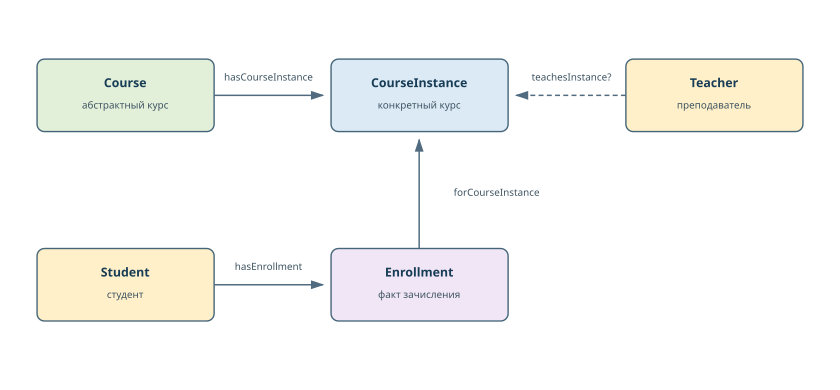

In [11]:
svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="840" height="390" viewBox="0 0 1020 470">
  <rect width="1020" height="470" fill="white"/>
  <defs>
    <marker id="a2" markerWidth="10" markerHeight="10" refX="8" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#506b7f"/>
    </marker>
  </defs>
  <style>
    .n{stroke:#456579;stroke-width:1.7}
    .t{font:700 15px sans-serif;fill:#173c55;text-anchor:middle}
    .s{font:12px sans-serif;fill:#3d5361;text-anchor:middle}
    .e{stroke:#506b7f;stroke-width:1.8;marker-end:url(#a2)}
  </style>

  <rect x="45" y="70" width="215" height="88" rx="9" fill="#e2efd9" class="n"/>
  <text x="152" y="104" class="t">Course</text>
  <text x="152" y="130" class="s">абстрактный курс</text>

  <rect x="402" y="70" width="215" height="88" rx="9" fill="#dceaf5" class="n"/>
  <text x="509" y="104" class="t">CourseInstance</text>
  <text x="509" y="130" class="s">конкретный курс</text>

  <rect x="760" y="70" width="215" height="88" rx="9" fill="#fff0c9" class="n"/>
  <text x="867" y="104" class="t">Teacher</text>
  <text x="867" y="130" class="s">преподаватель</text>

  <line x1="260" y1="114" x2="392" y2="114" class="e"/>
  <text x="326" y="96" class="s">hasCourseInstance</text>

  <line x1="760" y1="114" x2="627" y2="114" class="e" stroke-dasharray="6,4"/>
  <text x="694" y="96" class="s">teachesInstance?</text>

  <rect x="402" y="300" width="215" height="88" rx="9" fill="#f1e6f5" class="n"/>
  <text x="509" y="334" class="t">Enrollment</text>
  <text x="509" y="360" class="s">факт зачисления</text>

  <rect x="45" y="300" width="215" height="88" rx="9" fill="#fff0c9" class="n"/>
  <text x="152" y="334" class="t">Student</text>
  <text x="152" y="360" class="s">студент</text>

  <line x1="260" y1="344" x2="392" y2="344" class="e"/>
  <text x="326" y="326" class="s">hasEnrollment</text>

  <line x1="509" y1="300" x2="509" y2="168" class="e"/>
  <text x="603" y="236" class="s">forCourseInstance</text>
</svg>
"""
display(SVG(svg))

### Идентификаторы и правила именования

После того как основные классы и свойства определены, им нужно назначить устойчивые IRI. Необходимо отметить, что одинаковое текстовое название ещё не делает два объекта одним ресурсом.

Для университетского примера используется пространство имён:

```turtle
@prefix uni: <https://example.org/university/> .
```

Здесь:

- `uni:` - короткое имя префикса;
- `https://example.org/university/` - базовая часть IRI;
- `uni:Course` разворачивается в `https://example.org/university/Course`;
- `uni:SemTech` разворачивается в `https://example.org/university/SemTech`.

В рабочем проекте хороший IRI должен быть:

- устойчивым во времени;
- контролируемым владельцем данных;
- независимым от языка интерфейса;
- по возможности разрешаемым по HTTP(S);
- построенным по документированному правилу.

Полезно различать IRI словаря и IRI данных. Например:

```text
https://data.example.edu/ontology/Course
https://data.example.edu/id/course/semtech
```

В первом случае идентифицируется термин онтологии, во втором - конкретный курс.

Практическое соглашение об именовании:

- классы начитаются с верхнего регистра, например `EducationalProgram`;
- свойства начитаются с нижнего регистра, например `studiesCourse`;
- экземпляры - устойчивые коды или понятные локальные имена;
- метки`rdfs:label` на естественном языке с языковым тегом, например `"Курс"@ru`.


### Публичные словари

Создавать все термины с нуля обычно невыгодно. Если подходящее общее понятие уже существует в устойчивом публичном словаре, его переиспользование делает данные понятнее внешним системам и уменьшает число несовместимых локальных обозначений.

**Schema.org** предоставляет широкий словарь для структурированных веб-данных. В университетской модели используются, например, `Course`, `CourseInstance`, `Person`, `Organization`, `name`, `description`, `provider`, `courseCode`.

**FOAF** исторически важен для описания людей, документов и социальных связей. При этом `foaf:knows` слишком общий для точного отношения "студент изучает курс" или "преподаватель ведёт курс".

**Dublin Core Terms** предоставляет общие свойства метаданных: название, создатель, дата, язык, тема, лицензия, источник.

**SKOS** применяется для тезаурусов, классификаторов и систем понятий: предпочтительные термины, более широкие и узкие понятия, ассоциативные связи.

Необходиом отметить, что переиспользование полезно только тогда, когда совпадает **смысл**, а не просто название. Неверно выбранный внешний термин может сделать модель менее точной, чем аккуратно созданный локальный.

### Как принять решение о переиспользовании

Цель данного этапа понять, какие общие элементы модели действительно уже стандартизованы и пригодны для интеграции.

Последовательность решения:

1. записать точное определение локального понятия;
2. найти кандидатов в Schema.org, FOAF, Dublin Core Terms, SKOS или другом подходящем словаре;
3. сравнить официальное определение, область применения, ожидаемые значения и примеры;
4. проверить устойчивость пространства имён и поддержку словаря;
5. решить, не является ли внешний термин слишком широким или слишком узким;
6. выбрать один из вариантов:
   - использовать внешний термин напрямую;
   - создать локальный подкласс или подсвойство;
   - оставить локальный термин и документировать сопоставление;
   - отказаться от сопоставления, если смысл различается;
7. записать принятое решение и его обоснование;
8. проверить решение на тестовом факте или запросе.

Например, локальный `uni:Teacher` можно сделать подклассом общего `schema:Person`, если в университетской модели нужно отдельно фиксировать учебную роль преподавателя. В этом случае `schema:Person` переиспользуется как общий класс человека, а специфическая роль остаётся локальной.

In [12]:
show_table(
    ["Словарь", "Примеры терминов", "Когда полезен"],
    [
        ["Schema.org", "Course, CourseInstance, Person, Organization", "публикация каталога в веб"],
        ["FOAF", "Person, name, homepage, knows", "описание людей и социальных связей"],
        ["Dublin Core Terms", "title, creator, modified, license, subject", "общие метаданные"],
        ["SKOS", "Concept, broader, narrower, prefLabel", "тезаурусы и тематические рубрики"],
        ["Локальный словарь", "Teacher, studiesCourse, partOfProgram", "специфические учебные отношения"],
    ]
)

Словарь,Примеры терминов,Когда полезен
Schema.org,"Course, CourseInstance, Person, Organization",публикация каталога в веб
FOAF,"Person, name, homepage, knows",описание людей и социальных связей
Dublin Core Terms,"title, creator, modified, license, subject",общие метаданные
SKOS,"Concept, broader, narrower, prefLabel",тезаурусы и тематические рубрики
Локальный словарь,"Teacher, studiesCourse, partOfProgram",специфические учебные отношения


**JSON-LD** - способ представить RDF-данные в синтаксисе JSON. Ключ `@context` связывает короткие имена с IRI, `@type` задаёт тип ресурса, `@id` - его идентификатор.

Минимальная карточка курса:

```json
{
  "@context": "https://schema.org",
  "@type": "Course",
  "@id": "https://data.example.edu/id/course/semtech",
  "courseCode": "ST-201",
  "name": "Семантические технологии",
  "provider": {
    "@id": "https://data.example.edu/id/org/university",
    "@type": "CollegeOrUniversity",
    "name": "Примерный университет"
  }
}
```

В следующей исполняемой ячейке RDFLib разбирает JSON-LD в RDF-граф и выполняет SPARQL-запрос.

In [13]:
jsonld_text = r"""
{
  "@context": {
    "schema": "https://schema.org/",
    "name": "schema:name",
    "courseCode": "schema:courseCode",
    "provider": {"@id": "schema:provider", "@type": "@id"}
  },
  "@type": "schema:Course",
  "@id": "https://data.example.edu/id/course/semtech",
  "courseCode": "ST-201",
  "name": "Семантические технологии",
  "provider": "https://data.example.edu/id/org/university"
}
"""

jsonld_graph = Graph()
jsonld_graph.parse(data=jsonld_text, format="json-ld")
print("RDFLib преобразовал JSON-LD в RDF. Число троек:", len(jsonld_graph))

query_jsonld = """
PREFIX schema: <https://schema.org/>
SELECT ?course ?name ?code
WHERE {
  ?course a schema:Course ;
          schema:name ?name ;
          schema:courseCode ?code .
}
"""
show_sparql_result(jsonld_graph, query_jsonld)

RDFLib преобразовал JSON-LD в RDF. Число троек:

 4


course,name,code
https://data.example.edu/id/course/semtech,Семантические технологии,ST-201


## 4. Пример концептуальной модели университета

### Исходная ситуация

В рамках университета необходимо объединить сведения из:

- учебного плана;
- сайта кафедры;
- внутренней системы дистанционного обучения.

Источники используют разные поля, поэтому задача состоит не в механическом объединении таблиц, а в поиске общей концептуальной модели.

Главное решение - **разделять абстрактный учебный курс и его фактическую реализацию в конкретном семестре**.
`Course` описывает устойчивое учебное содержание, а `CourseInstance` - конкретную реализацию в определённый период.
Кроме того, если преподаватель назначается на конкретный курс в конкретном семестре, связи `Teacher → Course` недостаточно для ответа на вопрос "кто ведёт именно это проведение?". В этом случае модель должна либо добавить отношение к `CourseInstance`, либо явно зафиксировать, что такой вопрос выходит за её текущие границы.

Проверим, какие сведения приходят из разных источников.

In [14]:
show_table(
    ["Источник", "Пример данных"],
    [
        ["Учебный план", "код дисциплины, название, зачётные единицы, программа"],
        ["Сайт кафедры", "название курса, преподаватель, описание, материалы"],
        ["Система обучения", "поток, участники, даты, статус прохождения"],
    ]
)

Источник,Пример данных
Учебный план,"код дисциплины, название, зачётные единицы, программа"
Сайт кафедры,"название курса, преподаватель, описание, материалы"
Система обучения,"поток, участники, даты, статус прохождения"


Таблица источников показывает, что одинаковые сущности описываются разными наборами полей. Поэтому следующий шаг - не копирование столбцов, а **классификация терминов по их роли в модели**.

Для начала распределим элементы по классам, экземплярам, свойствам и значениям.

In [15]:
show_table(
    ["Термин", "Категория", "Комментарий"],
    [
        ["Студент", "класс", "множество лиц с учебным статусом"],
        ["Анна Смирнова", "экземпляр", "конкретный человек"],
        ["Курс", "класс", "требует определения: курс или проведение"],
        ["Семантические технологии", "экземпляр", "конкретный курс каталога"],
        ["изучает", "объектное свойство", "связь студента и курса"],
        ["3 зачётные единицы", "значение", "число с предметным смыслом"],
        ["осенний семестр", "экземпляр/период", "лучше моделировать отдельно"],
        ["электронная почта", "свойство данных", "публикация зависит от политики доступа"],
    ]
)

Термин,Категория,Комментарий
Студент,класс,множество лиц с учебным статусом
Анна Смирнова,экземпляр,конкретный человек
Курс,класс,требует определения: курс или проведение
Семантические технологии,экземпляр,конкретный курс каталога
изучает,объектное свойство,связь студента и курса
3 зачётные единицы,значение,число с предметным смыслом
осенний семестр,экземпляр/период,лучше моделировать отдельно
электронная почта,свойство данных,публикация зависит от политики доступа


После первичной классификации становится видно, что слово "курс" употребляется на разных уровнях. Чтобы свойства не смешивались, разделим абстрактное описание курса и конкретное проведение.

**Разделение `Course` и `CourseInstance`.**

```text
Course --hasCourseInstance--> CourseInstance
```

У абстрактного `Course` находятся свойства, устойчивые относительно семестра:

- название;
- код;
- описание содержания;
- зачётные единицы;
- принадлежность программе.

У `CourseInstance` находятся свойства связанные с проведением конкретного курса:

- дата начала;
- семестр;
- поток;
- конкретные участники.

Если факт участия студента имеет собственные атрибуты, используется `Enrollment`.

Следующий шаг - зафиксировать паспорт модели.

**Паспорт модели**

Паспорт модели — это краткое описание назначения модели, её пользователей, границ и источников терминов.

В части примера паспорт модели выглядит следующим образом:

- название: `University Course Ontology`, краткий префикс `uni`;
- назначение: интеграция сведений о курсах, преподавателях, программах и проведениях;
- пользователи: разработчики интеграции, учебный отдел, администраторы каталога, внешние приложения;
- включаются: курсы, проведения, программы, кафедры, преподаватели, студенты и основные учебные связи;
- исключаются: зарплата, кадровые приказы, детальное расписание аудиторий, персональные оценки в открытом наборе;
- источники терминов: Schema.org для общих типов и свойств, FOAF при необходимости описания людей, Dublin Core Terms для метаданных и локальный словарь для специфических учебных отношений.


**Компетентностные вопросы.**

1. Как называется курс с кодом ST-201?
2. Какие курсы входят в программу "Прикладная информатика"?
3. Какие проведения существуют у курса?
4. Кто ведёт курс?
5. На какой кафедре состоит преподаватель?
6. Какие студенты изучают курс?
7. У каких курсов отсутствует описание?
8. Какие экземпляры `Teacher` должны в дальнейшем находиться как `Person` после учёта иерархии?

Для сложного вопроса должен существовать путь по модели. Например:

```text
Teacher --teachesCourse--> Course --partOfProgram--> EducationalProgram
Student --hasEnrollment--> Enrollment --forCourseInstance--> CourseInstance
```

Вопрос "Кто ведёт конкретный курс?" все еще целесообразно использовать для выявления скрытых проблем. Если преподаватель назначается именно на семестровый поток, потребуется дополнительное отношение к `CourseInstance`.

После этой проверки модель можно представить в виде согласованного набора классов и свойств, а затем проверить на RDF-графе через RDFLib.

In [16]:
show_table(
    ["Класс", "Определение", "Родитель"],
    [
        ["Person", "физическое лицо в учебном процессе", "—"],
        ["Student", "лицо, зачисленное на программу", "Person"],
        ["Teacher", "лицо, ведущее учебные занятия", "Person"],
        ["Course", "абстрактная единица учебного содержания", "EducationalEntity"],
        ["CourseInstance", "конкретное проведение курса", "EducationalEntity"],
        ["EducationalProgram", "совокупность курсов и требований", "EducationalEntity"],
        ["Department", "подразделение университета", "Organization"],
        ["University", "образовательная организация", "Organization"],
    ]
)

show_table(
    ["Свойство", "Домен", "Диапазон / тип", "Смысл"],
    [
        ["studiesCourse", "Student", "Course", "студент изучает курс"],
        ["teachesCourse", "Teacher", "Course", "преподаватель ведёт курс"],
        ["partOfProgram", "Course", "EducationalProgram", "курс входит в программу"],
        ["memberOfDepartment", "Person", "Department", "лицо относится к кафедре"],
        ["credits", "Course", "xsd:decimal", "объём курса"],
        ["fullName", "Person", "rdf:langString", "полное имя"],
    ]
)

Класс,Определение,Родитель
Person,физическое лицо в учебном процессе,—
Student,"лицо, зачисленное на программу",Person
Teacher,"лицо, ведущее учебные занятия",Person
Course,абстрактная единица учебного содержания,EducationalEntity
CourseInstance,конкретное проведение курса,EducationalEntity
EducationalProgram,совокупность курсов и требований,EducationalEntity
Department,подразделение университета,Organization
University,образовательная организация,Organization


Свойство,Домен,Диапазон / тип,Смысл
studiesCourse,Student,Course,студент изучает курс
teachesCourse,Teacher,Course,преподаватель ведёт курс
partOfProgram,Course,EducationalProgram,курс входит в программу
memberOfDepartment,Person,Department,лицо относится к кафедре
credits,Course,xsd:decimal,объём курса
fullName,Person,rdf:langString,полное имя


### Проверка через RDFLib

SPARQL используется в качестве **теста концептуальной модели**:

1. `ontology_draft.ttl` загружается в объект `rdflib.Graph`;
2. RDFLib разбирает Turtle;
3. текст SPARQL передаётся напрямую в `Graph.query()`;
4. результат выводится таблицей.

Необходимо отметить, что RDFLib проверяют **явно записанные тройки**. 

Если загружается собственный `ontology_draft.ttl`, Python-код загрузки менять не требуется. Для своей модели меняется только текст SPARQL и используемые в нём IRI.

In [17]:
query_classes = """
PREFIX uni:  <https://example.org/university/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?class ?label
WHERE {
  ?class a rdfs:Class .
  FILTER(STRSTARTS(STR(?class), STR(uni:)))
  OPTIONAL {
    ?class rdfs:label ?label .
    FILTER(LANG(?label) = "ru")
  }
}
ORDER BY ?class
"""
show_sparql_result(draft_graph, query_classes)

class,label


Запрос выполнен, строк результата нет.


In [18]:
# Компетентностный вопрос: как называется курс с кодом ST-201?
competency_graph = Graph().parse(data=ONTOLOGY_DRAFT_TEMPLATE, format="turtle")

query_course_by_code = """
PREFIX uni:  <https://example.org/university/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?course ?label
WHERE {
  ?course uni:courseCode "ST-201" .
  OPTIONAL {
    ?course rdfs:label ?label .
    FILTER(LANG(?label) = "ru")
  }
}
"""
show_sparql_result(competency_graph, query_course_by_code);


course,label
https://example.org/university/SemTech,Семантические технологии


In [19]:
# Компетентностный вопрос с цепочкой отношений:
# какие преподаватели ведут курсы определённой программы?
competency_graph = Graph().parse(data=ONTOLOGY_DRAFT_TEMPLATE, format="turtle")

query_teacher_program = """
PREFIX uni:  <https://example.org/university/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?teacherName ?courseLabel ?programLabel
WHERE {
  ?teacher a uni:Teacher ;
           uni:fullName ?teacherName ;
           uni:teachesCourse ?course .

  ?course uni:partOfProgram ?program .

  OPTIONAL {
    ?course rdfs:label ?courseLabel .
    FILTER(LANG(?courseLabel) = "ru")
  }
  OPTIONAL {
    ?program rdfs:label ?programLabel .
    FILTER(LANG(?programLabel) = "ru")
  }
}
"""
show_sparql_result(competency_graph, query_teacher_program);


teacherName,courseLabel,programLabel
Елена Петрова,Семантические технологии,Прикладная информатика


После запросов полезно сделать ещё одну проверку: модель должна уметь выразить обычные словесные факты предметной области без искусственных конструкций.

**Проверка тестовыми фактами.**

1. Анна является студентом.
2. Курс "Семантические технологии" имеет код ST-201.
3. Осеннее проведение начинается 1 сентября 2026 года.
4. Курс входит в программу "Прикладная информатика".
5. Анна изучает курс.
6. Анна имеет зачисление на конкретное проведение.
7. Елена Петрова ведёт курс.

Если факт нельзя выразить имеющимися классами и свойствами, модель нужно уточнить до перехода к полной формализации.

### Типовые ошибки концептуального моделирования

После построения рабочего примера полезно целенаправленно проверить модель на типовые ошибки.

1. **Класс и экземпляр смешаны.**  
   Если `SemTech` обозначает конкретный курс, он является экземпляром `Course`, а не подклассом.

2. **Отношение заменено строкой.**  
   Если кафедра участвует в других связях, запись строки `"Кафедра ИИ"` хуже отдельного ресурса `uni:AIDepartment`.

3. **Иерархия используется вместо композиции.**  
   `Course subClassOf EducationalProgram` неверно: курс входит в программу, но не является программой.

4. **Иерархия слишком глубокая.**  
   Классы, которые не нужны данным, запросам и правилам, усложняют модель.

5. **Свойства слишком общие.**  
   `relatedTo` почти не сообщает машине предметного смысла. Лучше `teachesCourse`, `partOfProgram`, `memberOfDepartment`.

6. **Внешний термин выбран только по названию.**  
   Нужно сравнить официальное определение и область применения.

7. **Преждевременно используется `owl:sameAs`.**  
   Полное тождество нельзя использовать для просто похожих объектов.

8. **Термины не имеют определения.**  
   Название `Program` без контекста неоднозначно.


**Что сохранить после семинара.**

К следующему занятию оставьте рабочие файлы в отдельной папке вместе с notebook. Основной файл для продолжения: `ontology_draft.ttl`.

Перед сдачей:

1. откройте файл как текст и убедитесь, что это Turtle, а не переименованный `.txt`;
2. проверьте кодировку UTF-8;
3. убедитесь, что IRI и префиксы согласованы;
4. загрузите `ontology_draft.ttl` через RDFLib без ошибок;
5. выполните минимум два проверочных SPARQL-запроса через `Graph.query()`;
6. сохраните исходную версию черновика отдельно.

На следующем Семинаре этот черновик будет преобразован в более полную схему `ontology.ttl` и набор экземпляров `data.ttl`.

## 5. Индивидуальное задание

Для своего варианта необходимо:

1. сформулировать назначение и границы онтологии;
2. определить пользователей и сценарии;
3. составить не менее 8 компетентностных вопросов;
4. описать не менее 8 классов;
5. построить иерархию классов;
6. определить не менее 8 объектных свойств;
7. определить не менее 6 свойств данных;
8. привести не менее 5 экземпляров-примеров;
9. найти не менее 5 терминов Schema.org, FOAF, Dublin Core Terms или SKOS, которые можно переиспользовать;
10. для каждого внешнего термина объяснить решение: использовать напрямую, создать локальный подкласс/подсвойство или отказаться от сопоставления;
11. проверить модель на 5–7 словесных фактах;
12. подготовить `ontology_draft.ttl`;
13. проверить синтаксис файла через RDFLib;
14. составить минимум два SPARQL-запроса по компетентностным вопросам и выполнить их через `Graph.query()`.


In [20]:
N_STUDENTS = 80

domains = [
    ("Электронная библиотека",
     ["Произведение", "Издание", "Экземпляр", "Автор", "Читатель"],
     "различить произведение, издание и физический экземпляр"),
    ("Научная конференция",
     ["Мероприятие", "Секция", "Доклад", "Автор", "Рецензия"],
     "смоделировать авторство с порядком авторов"),
    ("Музейная коллекция",
     ["Объект", "Коллекция", "Автор", "Материал", "Выставка"],
     "связать объект с внешним идентификатором"),
    ("Городской транспорт",
     ["Маршрут", "Остановка", "Рейс", "Транспортное средство", "Оператор"],
     "различить маршрут и конкретный рейс"),
    ("Интернет-магазин",
     ["Товар", "Предложение", "Продавец", "Цена", "Категория"],
     "различить товар и коммерческое предложение"),
    ("Учебная платформа",
     ["Курс", "Модуль", "Задание", "Попытка", "Пользователь"],
     "смоделировать попытку выполнения как отдельную сущность"),
]

profiles = [
    ("Schema.org", "обязателен минимум один внешний класс"),
    ("FOAF", "сравнить точное локальное отношение с более общим внешним"),
    ("Dublin Core Terms", "добавить метаданные названия, даты и лицензии"),
    ("SKOS", "отделить тематическое понятие от OWL-класса"),
    ("CourseInstance-аналог", "разделить абстрактный объект и его реализацию"),
    ("n-арное отношение", "одно отношение представить промежуточной сущностью"),
    ("роль человека", "допустить один объект одновременно в двух совместимых ролях"),
    ("политика IRI", "предложить устойчивую схему IRI для классов и экземпляров"),
    ("многоязычные метки", "добавить русские и английские rdfs:label для ключевых терминов"),
    ("аннотации", "для ключевых классов добавить rdfs:label и rdfs:comment"),
    ("компетентностный путь", "один вопрос должен требовать цепочку минимум из двух отношений"),
    ("проверка subClassOf", "для трёх связей применить тест «каждый A является B»"),
    ("отказ от переиспользования", "для одного локального термина обосновать отказ от внешнего аналога"),
    ("класс и экземпляр", "выбрать один спорный термин и обосновать его категорию"),
]

rows = []
for i in range(N_STUDENTS):
    domain, entities, complexity = domains[i % len(domains)]
    vocab, extra = profiles[(i // len(domains)) % len(profiles)]
    rows.append([
        i + 1,
        domain,
        ", ".join(entities),
        complexity,
        vocab,
        extra,
    ])

show_table(
    ["Вариант", "Предметная область", "Обязательные сущности",
     "Обязательная сложность", "Фокус публичного словаря", "Дополнительное условие"],
    rows
)

Вариант,Предметная область,Обязательные сущности,Обязательная сложность,Фокус публичного словаря,Дополнительное условие
1,Электронная библиотека,"Произведение, Издание, Экземпляр, Автор, Читатель","различить произведение, издание и физический экземпляр",Schema.org,обязателен минимум один внешний класс
2,Научная конференция,"Мероприятие, Секция, Доклад, Автор, Рецензия",смоделировать авторство с порядком авторов,Schema.org,обязателен минимум один внешний класс
3,Музейная коллекция,"Объект, Коллекция, Автор, Материал, Выставка",связать объект с внешним идентификатором,Schema.org,обязателен минимум один внешний класс
4,Городской транспорт,"Маршрут, Остановка, Рейс, Транспортное средство, Оператор",различить маршрут и конкретный рейс,Schema.org,обязателен минимум один внешний класс
5,Интернет-магазин,"Товар, Предложение, Продавец, Цена, Категория",различить товар и коммерческое предложение,Schema.org,обязателен минимум один внешний класс
6,Учебная платформа,"Курс, Модуль, Задание, Попытка, Пользователь",смоделировать попытку выполнения как отдельную сущность,Schema.org,обязателен минимум один внешний класс
7,Электронная библиотека,"Произведение, Издание, Экземпляр, Автор, Читатель","различить произведение, издание и физический экземпляр",FOAF,сравнить точное локальное отношение с более общим внешним
8,Научная конференция,"Мероприятие, Секция, Доклад, Автор, Рецензия",смоделировать авторство с порядком авторов,FOAF,сравнить точное локальное отношение с более общим внешним
9,Музейная коллекция,"Объект, Коллекция, Автор, Материал, Выставка",связать объект с внешним идентификатором,FOAF,сравнить точное локальное отношение с более общим внешним
10,Городской транспорт,"Маршрут, Остановка, Рейс, Транспортное средство, Оператор",различить маршрут и конкретный рейс,FOAF,сравнить точное локальное отношение с более общим внешним


## 6. Выполнение индивидуального задания — вариант 57

Расчёт варианта выполняется по формуле из задания: для `N = 57` используется индекс `i = 56`.  
`56 mod 6 = 2` → **«Музейная коллекция»**; `floor(56 / 6) = 9` → профиль **«аннотации»**.

**Обязательные элементы варианта:** музейный объект, коллекция, автор, материал и выставка.  
**Обязательная сложность:** связать объект с внешним идентификатором.  
**Дополнительное условие:** добавить `rdfs:label` и `rdfs:comment` для ключевых классов.

### 6.1. Назначение, границы, пользователи и сценарии

**Назначение модели:** интегрировать каталог музейных объектов с данными о коллекциях, авторах, материалах, выставках, местах хранения и внешних идентификаторах. Модель предназначена для поиска, публикации открытых метаданных и проверки полноты каталожных записей.

**В границах модели:** созданные человеком музейные объекты, их авторство, материалы, коллекции, выставки, места, организаторы, темы и идентификаторы.

**Вне границ модели:** реставрационные процессы, страховая стоимость, перемещения между фондами, персональные данные посетителей, продажа билетов и правовой анализ авторского права. Природоведческие образцы исключены, поэтому локальный `MuseumObject` можно связать с `schema:CreativeWork`.

**Пользователи:** хранитель фонда, каталогизатор, куратор выставки, исследователь, разработчик музейного портала и специалист по интеграции данных.

**Сценарии:** регистрация нового объекта; поиск объектов одного автора или материала; формирование состава коллекции и выставки; поиск объектов без внешнего идентификатора; связывание записи с внешним каталогом; публикация карточки объекта.

**Политика IRI:** термины схемы находятся в `https://example.org/museum/ontology/`, экземпляры — в `https://example.org/museum/id/`; классы именуются в `UpperCamelCase`, свойства — в `lowerCamelCase`, экземпляры получают устойчивые коды, не зависящие от русской подписи.

### 6.2. Компетентностные вопросы

1. Как называется музейный объект с заданным инвентарным номером?
2. Кто является автором выбранного музейного объекта?
3. В какую коллекцию входит объект?
4. Из каких материалов изготовлен объект?
5. На каких выставках показывался объект?
6. Где проходит выбранная выставка и какая организация её проводит?
7. Какие объекты определённого автора входят в заданную коллекцию?
8. Какие объекты не имеют внешнего идентификатора?
9. Какой внешний ресурс однозначно идентифицирует объект?
10. Какие объекты коллекции, выполненные из заданного материала, показаны на выбранной выставке?

Вопрос 10 требует цепочки минимум из трёх отношений:  
`Collection → hasMember → MuseumObject → madeOf → MaterialConcept` и `MuseumObject → shownAt → Exhibition`.

### 6.3. Классы и иерархия

| Класс | Родитель / внешний класс | Назначение |
|---|---|---|
| `MuseumEntity` | — | общий корень локальной модели |
| `Agent` | `MuseumEntity` | лицо или организация |
| `MuseumObject` | `MuseumEntity`, `schema:CreativeWork` | объект музейного учёта |
| `Artwork` | `MuseumObject` | произведение искусства |
| `Document` | `MuseumObject` | музейный документ |
| `Creator` | `Agent`, `schema:Person` | автор объекта |
| `MuseumOrganization` | `Agent`, `schema:Organization` | музей или организатор |
| `Collection` | `MuseumEntity` | курируемая совокупность объектов |
| `Exhibition` | `MuseumEntity`, `schema:Event` | событие публичного показа |
| `MaterialConcept` | `MuseumEntity`, `skos:Concept` | материал как понятие справочника |
| `MuseumLocation` | `MuseumEntity`, `schema:Place` | место хранения или показа |

Проверка `subClassOf`: каждое `Artwork` является `MuseumObject`; каждый `Creator` является `Agent`; каждая `Exhibition` является `MuseumEntity`. Связь «объект входит в коллекцию» не является наследованием и задаётся свойством.

### 6.4. Свойства модели

**Объектные свойства (9):**

| Свойство | Домен → диапазон | Смысл |
|---|---|---|
| `hasMember` | `Collection → MuseumObject` | коллекция содержит объект |
| `memberOfCollection` | `MuseumObject → Collection` | объект входит в коллекцию |
| `createdBy` | `MuseumObject → Creator` | авторство объекта |
| `madeOf` | `MuseumObject → MaterialConcept` | материал изготовления |
| `shownAt` | `MuseumObject → Exhibition` | участие в выставке |
| `locatedAt` | `MuseumEntity → MuseumLocation` | место хранения или показа |
| `curatedBy` | `Exhibition → schema:Person` | куратор выставки |
| `organizedBy` | `Exhibition → MuseumOrganization` | организатор выставки |
| `hasSubject` | `MuseumObject → skos:Concept` | тема объекта |

**Свойства данных (6):**

| Свойство | Домен → тип | Смысл |
|---|---|---|
| `inventoryNumber` | `MuseumObject → xsd:string` | внутренний номер учёта |
| `creationYear` | `MuseumObject → xsd:gYear` | год создания |
| `acquisitionDate` | `MuseumObject → xsd:date` | дата поступления |
| `externalIdentifier` | `MuseumObject → xsd:anyURI` | URI внешней записи |
| `exhibitionStartDate` | `Exhibition → xsd:date` | дата открытия |
| `exhibitionEndDate` | `Exhibition → xsd:date` | дата закрытия |

Инвентарный номер и внешний идентификатор намеренно разделены: первый действует внутри музея, второй указывает на запись в другой системе.

### 6.5. Переиспользование публичных словарей

| Внешний термин | Решение | Обоснование |
|---|---|---|
| `schema:CreativeWork` | локальный подкласс | `MuseumObject` уже общего понятия творческой работы; область модели ограничена созданными человеком объектами |
| `schema:Person` | локальный подкласс | `Creator` — роль человека, а не любой человек |
| `schema:Organization` | локальный подкласс | музейная организация имеет более узкий смысл |
| `schema:Event` | локальный подкласс | выставка является специализированным событием |
| `schema:Place` | локальный подкласс | модели нужно отличать музейные места от произвольных мест |
| `schema:sameAs` | использовать напрямую | подходит только для URI, однозначно указывающего на тот же объект |
| `dcterms:title` | использовать напрямую | универсальное название ресурса, локальное свойство не требуется |
| `dcterms:description` | использовать напрямую | общее текстовое описание ресурса |
| `dcterms:creator` | локальное под-свойство | `createdBy` уже и связывает музейный объект именно с атрибутированным автором |
| `dcterms:identifier` | локальное под-свойство | `externalIdentifier` ограничен внешним URI и не заменяет внутренний номер |
| `skos:Concept`, `skos:prefLabel` | использовать напрямую | материалы и темы ведутся как понятия контролируемых справочников |
| `foaf:knows` | отказаться | личное знакомство не выражает ни авторство, ни кураторство, ни участие в выставке |

Таким образом, переиспользуется больше требуемых пяти терминов, но локальные понятия сохраняются там, где предметный смысл уже внешнего.

### 6.6. Проверка словесными фактами

Модель должна без искусственных конструкций выразить следующие факты:

1. «Черный квадрат (1930)» является произведением искусства.
2. Автор объекта — Казимир Малевич.
3. Объект входит в основную коллекцию русского авангарда.
4. Объект выполнен масляной краской.
5. Объект показан на выставке «Русский авангард: формы и идеи».
6. Выставка организована учебным музеем и проходит в выставочном зале № 1.
7. Внешняя запись объекта имеет URI `https://www.wikidata.org/entity/Q27970882`.

Все семь фактов представлены ниже RDF-тройками. Для внешнего URI дополнительно применяется `schema:sameAs`, поскольку ссылка заявлена как однозначная идентификация того же произведения.

In [21]:
ONTOLOGY_DRAFT_VARIANT_57 = r"""
@prefix mus: <https://example.org/museum/ontology/> .
@prefix id: <https://example.org/museum/id/> .
@prefix rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix schema: <https://schema.org/> .
@prefix dcterms: <http://purl.org/dc/terms/> .
@prefix skos: <http://www.w3.org/2004/02/skos/core#> .

mus: a rdfs:Resource ;
    dcterms:title "Черновик онтологии музейной коллекции"@ru ;
    dcterms:description "Вариант 57: каталогизация музейных объектов, коллекций, авторов, материалов и выставок."@ru .

# Классы
mus:MuseumEntity a rdfs:Class ;
    rdfs:label "Музейная сущность"@ru ;
    rdfs:comment "Общий локальный класс сущностей, учитываемых музейной информационной системой."@ru .

mus:Agent a rdfs:Class ;
    rdfs:subClassOf mus:MuseumEntity ;
    rdfs:label "Агент"@ru ;
    rdfs:comment "Лицо или организация, участвующие в создании, хранении либо показе объектов."@ru .

mus:MuseumObject a rdfs:Class ;
    rdfs:subClassOf mus:MuseumEntity, schema:CreativeWork ;
    rdfs:label "Музейный объект"@ru ;
    rdfs:comment "Созданный человеком объект, принятый на музейный учет и описываемый в каталоге."@ru .

mus:Artwork a rdfs:Class ;
    rdfs:subClassOf mus:MuseumObject ;
    rdfs:label "Произведение искусства"@ru ;
    rdfs:comment "Музейный объект, созданный как произведение изобразительного искусства."@ru .

mus:Document a rdfs:Class ;
    rdfs:subClassOf mus:MuseumObject ;
    rdfs:label "Документ"@ru ;
    rdfs:comment "Текстовый, графический или иной документ, хранящийся как музейный объект."@ru .

mus:Creator a rdfs:Class ;
    rdfs:subClassOf mus:Agent, schema:Person ;
    rdfs:label "Автор"@ru ;
    rdfs:comment "Физическое лицо, которому атрибутировано создание музейного объекта."@ru .

mus:MuseumOrganization a rdfs:Class ;
    rdfs:subClassOf mus:Agent, schema:Organization ;
    rdfs:label "Музейная организация"@ru ;
    rdfs:comment "Организация, которая хранит коллекцию или организует выставку."@ru .

mus:Collection a rdfs:Class ;
    rdfs:subClassOf mus:MuseumEntity ;
    rdfs:label "Коллекция"@ru ;
    rdfs:comment "Курируемая совокупность музейных объектов, объединенных происхождением или темой."@ru .

mus:Exhibition a rdfs:Class ;
    rdfs:subClassOf mus:MuseumEntity, schema:Event ;
    rdfs:label "Выставка"@ru ;
    rdfs:comment "Ограниченное во времени событие публичного показа музейных объектов."@ru .

mus:MaterialConcept a rdfs:Class ;
    rdfs:subClassOf mus:MuseumEntity, skos:Concept ;
    rdfs:label "Понятие материала"@ru ;
    rdfs:comment "Контролируемое понятие, обозначающее материал изготовления музейного объекта."@ru .

mus:MuseumLocation a rdfs:Class ;
    rdfs:subClassOf mus:MuseumEntity, schema:Place ;
    rdfs:label "Музейное место"@ru ;
    rdfs:comment "Здание, зал или иное место хранения либо показа объектов."@ru .

# Объектные свойства
mus:hasMember a rdf:Property ;
    rdfs:domain mus:Collection ; rdfs:range mus:MuseumObject ;
    rdfs:label "содержит объект"@ru .

mus:memberOfCollection a rdf:Property ;
    rdfs:domain mus:MuseumObject ; rdfs:range mus:Collection ;
    rdfs:label "входит в коллекцию"@ru .

mus:createdBy a rdf:Property ;
    rdfs:subPropertyOf dcterms:creator ;
    rdfs:domain mus:MuseumObject ; rdfs:range mus:Creator ;
    rdfs:label "создан автором"@ru .

mus:madeOf a rdf:Property ;
    rdfs:domain mus:MuseumObject ; rdfs:range mus:MaterialConcept ;
    rdfs:label "изготовлен из материала"@ru .

mus:shownAt a rdf:Property ;
    rdfs:domain mus:MuseumObject ; rdfs:range mus:Exhibition ;
    rdfs:label "показан на выставке"@ru .

mus:locatedAt a rdf:Property ;
    rdfs:domain mus:MuseumEntity ; rdfs:range mus:MuseumLocation ;
    rdfs:label "находится в месте"@ru .

mus:curatedBy a rdf:Property ;
    rdfs:domain mus:Exhibition ; rdfs:range schema:Person ;
    rdfs:label "курируется лицом"@ru .

mus:organizedBy a rdf:Property ;
    rdfs:domain mus:Exhibition ; rdfs:range mus:MuseumOrganization ;
    rdfs:label "организована организацией"@ru .

mus:hasSubject a rdf:Property ;
    rdfs:subPropertyOf dcterms:subject ;
    rdfs:domain mus:MuseumObject ; rdfs:range skos:Concept ;
    rdfs:label "имеет тему"@ru .

# Свойства данных
mus:inventoryNumber a rdf:Property ;
    rdfs:domain mus:MuseumObject ; rdfs:range xsd:string ;
    rdfs:label "инвентарный номер"@ru .

mus:creationYear a rdf:Property ;
    rdfs:domain mus:MuseumObject ; rdfs:range xsd:gYear ;
    rdfs:label "год создания"@ru .

mus:acquisitionDate a rdf:Property ;
    rdfs:domain mus:MuseumObject ; rdfs:range xsd:date ;
    rdfs:label "дата поступления"@ru .

mus:externalIdentifier a rdf:Property ;
    rdfs:subPropertyOf dcterms:identifier ;
    rdfs:domain mus:MuseumObject ; rdfs:range xsd:anyURI ;
    rdfs:label "внешний идентификатор"@ru .

mus:exhibitionStartDate a rdf:Property ;
    rdfs:domain mus:Exhibition ; rdfs:range xsd:date ;
    rdfs:label "дата открытия выставки"@ru .

mus:exhibitionEndDate a rdf:Property ;
    rdfs:domain mus:Exhibition ; rdfs:range xsd:date ;
    rdfs:label "дата закрытия выставки"@ru .

# Примеры экземпляров
id:DemoMuseum a mus:MuseumOrganization ;
    dcterms:title "Учебный музей русского авангарда"@ru .

id:MainCollection a mus:Collection ;
    dcterms:title "Основная коллекция русского авангарда"@ru ;
    mus:hasMember id:BlackSquare1930 .

id:Malevich a mus:Creator ;
    dcterms:title "Казимир Малевич"@ru .

id:OilPaint a mus:MaterialConcept ;
    skos:prefLabel "масляная краска"@ru .

id:AvantGarde a skos:Concept ;
    skos:prefLabel "русский авангард"@ru .

id:WinterPalaceHall a mus:MuseumLocation ;
    dcterms:title "Выставочный зал № 1"@ru .

id:RussianAvantGardeExhibition a mus:Exhibition ;
    dcterms:title "Русский авангард: формы и идеи"@ru ;
    mus:organizedBy id:DemoMuseum ;
    mus:locatedAt id:WinterPalaceHall ;
    mus:exhibitionStartDate "2026-09-01"^^xsd:date ;
    mus:exhibitionEndDate "2026-12-20"^^xsd:date .

id:BlackSquare1930 a mus:Artwork ;
    dcterms:title "Черный квадрат (1930)"@ru ;
    dcterms:description "Учебная запись музейного каталога для проверки модели."@ru ;
    mus:inventoryNumber "Ж-0001" ;
    mus:creationYear "1930"^^xsd:gYear ;
    mus:acquisitionDate "2020-05-15"^^xsd:date ;
    mus:externalIdentifier "https://www.wikidata.org/entity/Q27970882"^^xsd:anyURI ;
    schema:sameAs <https://www.wikidata.org/entity/Q27970882> ;
    mus:createdBy id:Malevich ;
    mus:madeOf id:OilPaint ;
    mus:memberOfCollection id:MainCollection ;
    mus:shownAt id:RussianAvantGardeExhibition ;
    mus:locatedAt id:WinterPalaceHall ;
    mus:hasSubject id:AvantGarde .
"""

variant_ttl_path = Path("ontology_draft.ttl")
variant_ttl_path.write_text(ONTOLOGY_DRAFT_VARIANT_57, encoding="utf-8")
print(f"Сохранено: {variant_ttl_path.resolve()}")

Сохранено: C:\Users\nasty\Semantic_technologies\ontology_draft.ttl


In [22]:
# Синтаксическая и структурная проверка варианта 57
MUS = Namespace("https://example.org/museum/ontology/")
ID = Namespace("https://example.org/museum/id/")

variant_graph = Graph()
variant_graph.parse("ontology_draft.ttl", format="turtle")

class_names = [
    "MuseumEntity", "Agent", "MuseumObject", "Artwork", "Document", "Creator",
    "MuseumOrganization", "Collection", "Exhibition", "MaterialConcept", "MuseumLocation"
]
object_property_names = [
    "hasMember", "memberOfCollection", "createdBy", "madeOf", "shownAt",
    "locatedAt", "curatedBy", "organizedBy", "hasSubject"
]
data_property_names = [
    "inventoryNumber", "creationYear", "acquisitionDate", "externalIdentifier",
    "exhibitionStartDate", "exhibitionEndDate"
]
example_names = [
    "DemoMuseum", "MainCollection", "Malevich", "OilPaint", "AvantGarde",
    "WinterPalaceHall", "RussianAvantGardeExhibition", "BlackSquare1930"
]

assert all((MUS[name], RDF.type, RDFS.Class) in variant_graph for name in class_names)
assert all((MUS[name], RDF.type, RDF.Property) in variant_graph for name in object_property_names)
assert all((MUS[name], RDF.type, RDF.Property) in variant_graph for name in data_property_names)
assert all(any(variant_graph.triples((ID[name], RDF.type, None))) for name in example_names)
assert all(any(variant_graph.objects(MUS[name], RDFS.label)) for name in class_names)
assert all(any(variant_graph.objects(MUS[name], RDFS.comment)) for name in class_names)

show_table(
    ["Проверка", "Результат"],
    [
        ["Turtle", "разобран RDFLib без ошибок"],
        ["Всего RDF-троек", len(variant_graph)],
        ["Локальные классы", len(class_names)],
        ["Объектные свойства", len(object_property_names)],
        ["Свойства данных", len(data_property_names)],
        ["Примеры экземпляров", len(example_names)],
        ["label/comment у ключевых классов", "проверены"],
    ],
)


Проверка,Результат
Turtle,разобран RDFLib без ошибок
Всего RDF-троек,148
Локальные классы,11
Объектные свойства,9
Свойства данных,6
Примеры экземпляров,8
label/comment у ключевых классов,проверены


### 6.7. SPARQL-проверки компетентностных вопросов

Первый запрос отвечает на вопросы 1, 2 и 9: находит объект по инвентарному номеру, его название, автора и внешний идентификатор.

In [23]:
query_object_card = """
PREFIX mus: <https://example.org/museum/ontology/>
PREFIX dcterms: <http://purl.org/dc/terms/>

SELECT ?object ?title ?creatorName ?externalId
WHERE {
  ?object mus:inventoryNumber "Ж-0001" ;
          dcterms:title ?title ;
          mus:createdBy ?creator ;
          mus:externalIdentifier ?externalId .
  ?creator dcterms:title ?creatorName .
}
"""
show_sparql_result(variant_graph, query_object_card)


object,title,creatorName,externalId
https://example.org/museum/id/BlackSquare1930,Черный квадрат (1930),Казимир Малевич,https://www.wikidata.org/entity/Q27970882


Второй запрос проверяет сложный путь из вопроса 10: от коллекции к объекту, затем к материалу и выставке.

In [24]:
query_collection_material_exhibition = """
PREFIX mus: <https://example.org/museum/ontology/>
PREFIX dcterms: <http://purl.org/dc/terms/>
PREFIX skos: <http://www.w3.org/2004/02/skos/core#>

SELECT ?objectTitle ?materialLabel ?exhibitionTitle
WHERE {
  ?collection dcterms:title "Основная коллекция русского авангарда"@ru ;
              mus:hasMember ?object .
  ?object dcterms:title ?objectTitle ;
          mus:madeOf ?material ;
          mus:shownAt ?exhibition .
  ?material skos:prefLabel ?materialLabel .
  ?exhibition dcterms:title ?exhibitionTitle .
}
"""
show_sparql_result(variant_graph, query_collection_material_exhibition)


objectTitle,materialLabel,exhibitionTitle
Черный квадрат (1930),масляная краска,Русский авангард: формы и идеи


Третий запрос отвечает на вопрос 8 и служит проверкой полноты каталога. В демонстрационных данных строк нет, потому что единственный музейный объект имеет внешний идентификатор.

In [25]:
query_missing_external_id = """
PREFIX mus: <https://example.org/museum/ontology/>
PREFIX dcterms: <http://purl.org/dc/terms/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?object ?title
WHERE {
  ?object a ?objectClass ;
          dcterms:title ?title .
  ?objectClass rdfs:subClassOf* mus:MuseumObject .
  FILTER NOT EXISTS { ?object mus:externalIdentifier ?externalId }
}
ORDER BY ?title
"""
show_sparql_result(variant_graph, query_missing_external_id)


object,title


Запрос выполнен, строк результата нет.


### 6.8. Итог

Требования варианта выполнены: определены назначение и границы, пользователи и сценарии, 10 компетентностных вопросов, 11 классов с иерархией и аннотациями, 9 объектных и 6 дататипных свойств, 8 экземпляров, решения по переиспользованию публичных словарей, 7 тестовых фактов, Turtle-файл и 3 исполняемых SPARQL-запроса.